# Generating Initial Diagnoses from Triage Records using Ollama

A small local LLM reads an emergency department triage record (chief complaint, vitals, pain, acuity, arrival mode, age and sex) and guesses the ICD-10 chapter of the diagnosis the ED later recorded. We compare three prompting techniques on the same visits and score them against the real ED diagnosis.

*Data: MIMIC-IV-ED Demo and MIMIC-IV Demo, PhysioNet, Open Data Commons ODbL v1.0.*

## Before you start

1. **Clone the repo.** The data is already in `data/`, so there is nothing to download.
2. **Make a virtual environment** in the repo folder: `python -m venv .venv`, then `source .venv/bin/activate` (Windows: `.venv\Scripts\activate`). If you use `uv venv`, add `--seed`; otherwise the environment has no pip and the install cell fails.
3. **Start Jupyter from that environment:** `pip install jupyter`, then `jupyter notebook`. In VS Code, open the repo folder itself and pick the `.venv` kernel.
4. **Install Ollama** from [ollama.com](https://ollama.com) and keep the app running. The setup cell downloads the model (~2 GB) the first time.
5. **Expect about 10 minutes** for the full run on a laptop. Most of it is the chain-of-thought prompt. Lower `N_CASES` in the config cell for a faster run.

## Step 1: Setup

We run the model locally with Ollama. The full MIMIC-IV-ED is credentialed data, and its data use agreement forbids sending records to an outside API such as ChatGPT. This tutorial uses the public demo instead: it is small enough to run on a laptop, and its open license lets us commit it to the repo, so anyone can run the notebook without a PhysioNet account. Because the model never leaves your machine, the same notebook would work unchanged on the credentialed data.

For reproducibility, the config cell prints the model's digest (the exact weights), and every call uses temperature 0 and a fixed seed.

In [1]:
# What: install the libraries this notebook uses.
# Why:  anyone cloning the repo can run it from scratch.
# You should see: "Successfully installed ..." or nothing (already installed).
%pip install -q pandas pydantic ollama scikit-learn matplotlib seaborn tqdm


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# What: settings you may want to change, plus imports.
# Why:  one place to change the model, the number of test cases and the seed.
#       The pull downloads the model into Ollama (needs the Ollama app running; ~2 GB the first time).
# You should see: "pull: success", then the model's details and digest.
from pathlib import Path
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ollama
from pydantic import BaseModel, ValidationError
from tqdm import tqdm

MODEL   = "qwen2.5:3b"   # local model served by Ollama
N_CASES = 1000           # max ED stays to score; more than the cohort = every stay (lower = faster)
SEED    = 42
DATA    = Path("data")

print("pull:", ollama.pull(MODEL).status)   # download if missing
print(ollama.show(MODEL).details)   # model family / size / quantization, for reproducibility
print("digest:", next(m.digest for m in ollama.list().models if m.model == MODEL))   # exact weights

pull: success
parent_model='' format='gguf' family='qwen2' families=['qwen2'] parameter_size='3.1B' quantization_level='Q4_K_M'
digest: 357c53fb659c5076de1d65ccb0b397446227b71a42be9d1603d46168015c9e4b


In [3]:
# What: time one call so you know how long the full run takes.
# You should see: a short reply and a time in seconds.
t0 = time.time()
r = ollama.chat(model=MODEL, messages=[{"role": "user", "content": "Name one ICD-10 chapter."}],
                options={"temperature": 0, "seed": SEED})
print(r.message.content, f"\n{time.time() - t0:.1f}s per call")

One ICD-10 chapter is "Injury, poisoning and certain other consequences of external causes" (T). 
3.6s per call


## Step 2: Data

This demo uses five tables, all committed to the repo: `edstays`, `triage`, `diagnosis`, `patients` and `d_icd_diagnoses`. We join them into one row per ED stay.

The prompt only includes fields known at triage, so it isn't polluted with the answer. We leave out `disposition`, `outtime`, `hadm_id` and the other diagnoses, because they're recorded after the diagnosis is made.

Age is an approximation based on `anchor_age`, the patient's age in their anchor year rather than on the day of the visit.

In [4]:
# What: load the 5 demo tables.
# You should see: the row count and columns of each table.
edstays   = pd.read_csv(DATA / "ed/edstays.csv.gz")
triage    = pd.read_csv(DATA / "ed/triage.csv.gz")
diagnosis = pd.read_csv(DATA / "ed/diagnosis.csv.gz")
patients  = pd.read_csv(DATA / "hosp/patients.csv.gz")
d_icd     = pd.read_csv(DATA / "hosp/d_icd_diagnoses.csv.gz")

for name, df in {"edstays": edstays, "triage": triage, "diagnosis": diagnosis,
                 "patients": patients, "d_icd_diagnoses": d_icd}.items():
    print(f"{name:16s} {len(df):>7,} rows  {list(df.columns)}")

edstays              222 rows  ['subject_id', 'hadm_id', 'stay_id', 'intime', 'outtime', 'gender', 'race', 'arrival_transport', 'disposition']
triage               222 rows  ['subject_id', 'stay_id', 'temperature', 'heartrate', 'resprate', 'o2sat', 'sbp', 'dbp', 'pain', 'acuity', 'chiefcomplaint']
diagnosis            545 rows  ['subject_id', 'stay_id', 'seq_num', 'icd_code', 'icd_version', 'icd_title']
patients             100 rows  ['subject_id', 'gender', 'anchor_age', 'anchor_year', 'anchor_year_group', 'dod']
d_icd_diagnoses  109,775 rows  ['icd_code', 'icd_version', 'long_title']


In [5]:
# What: one row per ED stay = triage-time features + the primary diagnosis (seq_num = 1).
# Why:  only information known at triage goes into the prompt. disposition, outtime,
#       hadm_id and the other diagnoses are left out (they would leak the answer).
# You should see: stay and patient counts; the assert passes.
primary = diagnosis.loc[diagnosis.seq_num == 1, ["stay_id", "icd_code", "icd_version", "icd_title"]]

cohort = (edstays[["subject_id", "stay_id", "gender", "arrival_transport"]]
          .merge(triage.drop(columns=["subject_id"], errors="ignore"), on="stay_id")
          .merge(patients[["subject_id", "anchor_age"]], on="subject_id")
          .merge(primary, on="stay_id"))

assert cohort.stay_id.is_unique
print(f"{len(edstays)} ED stays → {len(cohort)} with triage + primary diagnosis "
      f"({cohort.subject_id.nunique()} patients)")

222 ED stays → 221 with triage + primary diagnosis (63 patients)


In [6]:
# What: confirm the ICD dictionary is complete enough to check model codes against.
# You should see: tens of thousands of ICD-10 codes (the full ICD-10-CM list is ~70k+).
valid_icd10 = set(d_icd.loc[d_icd.icd_version == 10, "icd_code"].str.strip())
print(f"{len(valid_icd10):,} ICD-10 codes in the dictionary")
assert len(valid_icd10) > 50_000, "Dictionary looks partial; use the CMS ICD-10-CM code list instead"

95,109 ICD-10 codes in the dictionary


## Step 3: Labels

Instead of scoring whether the model matches the exact ICD code, we score the **chapter**, the top-level grouping of ICD-10. ICD-10 has 22 chapters, compared with about 95,000 codes, which makes this a problem a triage record can realistically answer.

Another complication in this dataset is that it covers years coded in ICD-9 as well as ICD-10. We have the model answer in ICD-10 and keep only the ICD-10 stays.

In [7]:
# What: map any ICD-10-CM code to its chapter (the label we classify into).
# Why:  exact codes are too fine-grained for a triage record; chapters are the
#       ICD grouping from the ICD lectures (4.1) and the LOS tutorial (Series 11).
# How:  the first 3 characters (the category) fall inside one chapter's range.
#       Plain string comparison works because the categories sort alphabetically.
ICD10_CHAPTERS = [
    ("A00", "B99", "Infectious"),          ("C00", "D49", "Neoplasms"),
    ("D50", "D89", "Blood & immune"),      ("E00", "E89", "Endocrine & metabolic"),
    ("F01", "F99", "Mental & behavioral"), ("G00", "G99", "Nervous system"),
    ("H00", "H59", "Eye"),                 ("H60", "H95", "Ear"),
    ("I00", "I99", "Circulatory"),         ("J00", "J99", "Respiratory"),
    ("K00", "K95", "Digestive"),           ("L00", "L99", "Skin"),
    ("M00", "M99", "Musculoskeletal"),     ("N00", "N99", "Genitourinary"),
    ("O00", "O9A", "Pregnancy"),           ("P00", "P96", "Perinatal"),
    ("Q00", "Q99", "Congenital"),          ("R00", "R99", "Symptoms & signs"),
    ("S00", "T88", "Injury & poisoning"),  ("U00", "U85", "Special purpose"),
    ("V00", "Y99", "External causes"),     ("Z00", "Z99", "Health-status factors"),
]

def clean_code(code: str) -> str:
    """'R07.9 ' -> 'R079' (MIMIC stores codes without dots)."""
    return code.strip().upper().replace(".", "")

def icd10_chapter(code: str) -> str:
    category = clean_code(code)[:3]
    if not re.fullmatch(r"[A-Z]\d[0-9A-Z]", category):   # letter, digit, digit/letter
        return "Unknown"
    for lo, hi, name in ICD10_CHAPTERS:
        if lo <= category <= hi:
            return name
    return "Unknown"

In [8]:
# What: checks for the chapter helper.
# You should see: "chapter tests pass".
assert icd10_chapter("R079")     == "Symptoms & signs"   # MIMIC format, no dot
assert icd10_chapter("R07.9")    == "Symptoms & signs"   # model format, with dot
assert icd10_chapter("I10")      == "Circulatory"
assert icd10_chapter("S0990XA")  == "Injury & poisoning"
assert icd10_chapter("T50901A")  == "Injury & poisoning"
assert icd10_chapter("D489")     == "Neoplasms"          # D00–D49
assert icd10_chapter("D500")     == "Blood & immune"     # D50–D89
assert icd10_chapter("H612")     == "Ear"                # H60–H95
assert icd10_chapter("O9A311")   == "Pregnancy"
assert icd10_chapter("XYZ")      == "Unknown"
print("chapter tests pass")

chapter tests pass


Dropped 99 ICD-9 stays → 122 ICD-10 stays


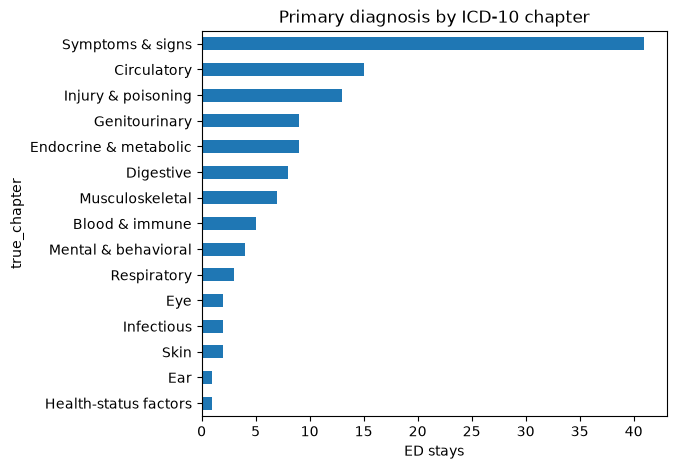

In [9]:
# What: keep ICD-10 stays (the model answers in ICD-10), then label each stay's chapter.
# You should see: how many ICD-9 stays were dropped, then a bar chart of chapters.
n_icd9 = (cohort.icd_version == 9).sum()
cohort = cohort[cohort.icd_version == 10].copy()
cohort["true_chapter"] = cohort.icd_code.map(icd10_chapter)
print(f"Dropped {n_icd9} ICD-9 stays → {len(cohort)} ICD-10 stays")

cohort.true_chapter.value_counts().plot.barh(figsize=(6, 5), title="Primary diagnosis by ICD-10 chapter")
plt.gca().invert_yaxis(); plt.xlabel("ED stays"); plt.show()

## Step 4: Prompt

We can't pass a DataFrame row to the model directly, so `make_prompt` writes each triage row as a short summary that an LLM can easily understand.

In [10]:
# What: turn one triage row into short text the model can read (table-to-prompt, as in CancerGPT).
# Why:  the LLM reads text, not a DataFrame row.
# You should see (next cell): one real triage summary.
def show(x, unit=""):
    return "not recorded" if pd.isna(x) else f"{x}{unit}"

def make_prompt(row) -> str:
    sex = {"M": "male", "F": "female"}.get(row.gender, "sex not recorded")
    return (f"Age {row.anchor_age}, {sex}. Arrived by {show(row.arrival_transport).lower()}.\n"
            f'Chief complaint: "{show(row.chiefcomplaint)}"\n'
            f"Triage vitals: T {show(row.temperature, '°F')}, HR {show(row.heartrate)}, "
            f"RR {show(row.resprate)}, SpO2 {show(row.o2sat, '%')}, "
            f"BP {show(row.sbp)}/{show(row.dbp)}. Pain {show(row.pain)}/10. "
            f"ESI acuity {show(row.acuity)}.")

print(make_prompt(cohort.iloc[0]))

Age 83, female. Arrived by ambulance.
Chief complaint: "Syncope, Transfer"
Triage vitals: T 97.7°F, HR 74.0, RR 20.0, SpO2 96.0%, BP 133.0/65.0. Pain 3/10. ESI acuity 2.0.


In [11]:
# What: the prompt must say "not recorded" for missing vitals, never "nan".
# You should see: "prompt tests pass".
_row = pd.Series({"anchor_age": 67, "gender": "M", "arrival_transport": "AMBULANCE",
                  "chiefcomplaint": "Chest pain", "temperature": np.nan, "heartrate": 112,
                  "resprate": 22, "o2sat": 93, "sbp": 148, "dbp": 90, "pain": "7", "acuity": 2})
_p = make_prompt(_row)
assert "nan" not in _p.lower() and "not recorded" in _p and "Chest pain" in _p
print("prompt tests pass")

prompt tests pass


## Step 5: Ask the model

All three prompts use the same system instruction and see the same stays:

- **Zero-shot:** the triage summary and the instruction, nothing else.
- **Few-shot:** three solved examples first, passed as earlier chat turns. They are picked by a fixed rule (the first stay from each of the three most common chapters), and every stay from those patients is removed from scoring, so the model is never scored on a patient it has been shown.
- **Chain-of-thought (CoT):** zero-shot plus an instruction to reason step by step. The `reasoning` field comes first in the answer schema, so the model writes its reasoning before it commits to a diagnosis.

Each technique is compared with zero-shot, so CoT is not stacked on top of few-shot.

The answer comes back as JSON. Passing the Pydantic schema to Ollama's `format=` makes the model follow that shape, and Pydantic then validates it. An answer that fails to parse counts as wrong.

In [12]:
# What: the JSON shape we want back (Pydantic, as in Practice 2), and one function that asks the model.
# Why:  Ollama's `format=` makes the model return JSON in this shape; Pydantic checks it.
#       In AnswerCoT `reasoning` comes first, so the model writes it before it answers.
class Answer(BaseModel):
    diagnosis: str   # plain-language diagnosis
    icd10: str       # ICD-10-CM code

class AnswerCoT(BaseModel):
    reasoning: str
    diagnosis: str
    icd10: str

SYSTEM = ("You review emergency department triage records. Give the single most likely "
          "diagnosis the ED will record and its ICD-10-CM code. Answer only in the JSON format requested.")

COT_HINT = "\nThink step by step in the reasoning field before giving the diagnosis."

def build_messages(row, technique: str) -> list[dict]:
    msgs = [{"role": "system", "content": SYSTEM}]
    if technique == "few_shot":                       # 3 worked examples as earlier chat turns
        for _, ex in examples.iterrows():
            msgs.append({"role": "user", "content": make_prompt(ex)})
            msgs.append({"role": "assistant",
                         "content": Answer(diagnosis=ex.icd_title, icd10=ex.icd_code).model_dump_json()})
    user = make_prompt(row) + (COT_HINT if technique == "cot" else "")
    msgs.append({"role": "user", "content": user})
    return msgs

def ask(row, technique: str):
    """Return (diagnosis, icd10, reasoning, parse_ok)."""
    schema = AnswerCoT if technique == "cot" else Answer
    resp = ollama.chat(model=MODEL, messages=build_messages(row, technique),
                       format=schema.model_json_schema(),
                       options={"temperature": 0, "seed": SEED,
                                "num_predict": 512})   # cap the answer length: small models can loop forever in JSON mode
    try:
        a = schema.model_validate_json(resp.message.content)
        return a.diagnosis, a.icd10, getattr(a, "reasoning", None), True
    except ValidationError:
        return None, None, None, False

In [13]:
# What: choose 3 fixed few-shot examples and the stays we score on.
# Why:  examples = the first stay (by stay_id) from each of the 3 most common chapters,
#       a fixed rule rather than a hand pick. Their patients are removed from the eval set,
#       so the model never gets scored on a case it was shown.
# You should see: the 3 examples' chapters, and the eval-set size.
top3 = cohort.true_chapter.value_counts().index[:3]
examples = (cohort[cohort.true_chapter.isin(top3)]
            .sort_values("stay_id").groupby("true_chapter").head(1))
eval_df = cohort[~cohort.subject_id.isin(examples.subject_id)]
eval_df = eval_df.sample(n=min(N_CASES, len(eval_df)), random_state=SEED)

print(examples[["stay_id", "chiefcomplaint", "icd_code", "true_chapter"]])
print(f"Evaluating on {len(eval_df)} stays from {eval_df.subject_id.nunique()} patients")

      stay_id        chiefcomplaint icd_code        true_chapter
194  30094124     Fatigue, s/p Fall     R531    Symptoms & signs
112  30115213  MVC/INTUBATED TRAUMA  S066X9A  Injury & poisoning
215  30272878              Transfer     I313         Circulatory
Evaluating on 94 stays from 29 patients


In [14]:
# What: try all three prompts on one eval stay before the full run.
# You should see: a diagnosis + ICD-10 code for each; CoT also shows its reasoning.
for t in ["zero_shot", "few_shot", "cot"]:
    print(t, ask(eval_df.iloc[0], t))

zero_shot ('I63.111 Optic neuritis, right eye, initial encounter for acute episode', 'I63.111', None, True)
few_shot ('Corneal ulcer of eye, unspecified', 'H56.1', None, True)
cot ('372.01 - Corneal abrasion of left eye, initial encounter for closed injury (for uncomplicated cases without complications or sequelae).', '372.01', "Given the patient's age, female gender, chief complaint of L eye pain, and triage vitals, the most likely diagnosis is a corneal abrasion. This is supported by the patient's ESI acuity of 3.0, indicating a significant visual impairment consistent with a corneal abrasion. The pain score of 7/10 further supports this diagnosis. The patient's vital signs are within normal limits, and there are no other symptoms that would suggest a different diagnosis.", True)


In [15]:
# What: ask the model about every eval stay with each of the 3 prompts.
# Why:  every prompt gets the same stays, so the accuracies are directly comparable.
# You should see: 3 progress bars; total time ≈ the speed check × 3 × N_CASES.
TECHNIQUES = ["zero_shot", "few_shot", "cot"]
rows = []
for technique in TECHNIQUES:
    for _, row in tqdm(eval_df.iterrows(), total=len(eval_df), desc=technique):
        dx, code, reasoning, ok = ask(row, technique)
        rows.append({"stay_id": row.stay_id, "technique": technique,
                     "true_code": row.icd_code, "true_chapter": row.true_chapter,
                     "pred_diagnosis": dx, "pred_code": code, "reasoning": reasoning, "parse_ok": ok})
results = pd.DataFrame(rows)
results.head()

cot: 100%|██████████| 94/94 [07:07<00:00,  4.55s/it]


,stay_id,technique,true_code,true_chapter,pred_diagnosis,pred_code,reasoning,parse_ok
0,37206743,zero_shot,R0600,Symptoms & signs,"I63.111 Optic neuritis, right eye, initial enc...",I63.111,NaN,True
1,39747335,zero_shot,M25562,Musculoskeletal,R Knee contusion,S72.81,NaN,True
2,33065303,zero_shot,I214,Circulatory,Atrial Fibrillation,I47.1,NaN,True
3,30225689,zero_shot,R109,Symptoms & signs,"Abdominal pain, unspecified",K25.9,NaN,True
4,34176810,zero_shot,R55,Symptoms & signs,Syncope,R55.9,NaN,True


## Step 6: Score

- **Accuracy:** the share of stays where the chapter of the model's code matches the chapter of the ED's primary diagnosis.
- **Invented code:** the share of returned codes that don't exist in the ICD-10 dictionary. A model can invent a code and still land in the right chapter, so this measures hallucination separately from accuracy.
- **Parse failed:** answers that weren't valid JSON, or that were cut off by the length cap.
- **Confusion matrix** (best prompt): rows are the true chapter, columns the predicted one. The diagonal is correct, and off-diagonal cells show which chapters get mixed up.

In [16]:
# What: score each prompt.
#   accuracy      = predicted chapter == true chapter (a failed parse counts as wrong)
#   invented_code = share of returned codes that don't exist in the ICD-10 dictionary
# You should see: one row per prompt.
results["pred_chapter"] = results.pred_code.map(lambda c: icd10_chapter(c) if isinstance(c, str) else "Parse failed")
results["correct"]      = results.pred_chapter == results.true_chapter
results["valid_code"]   = results.pred_code.map(lambda c: clean_code(c) in valid_icd10 if isinstance(c, str) else np.nan).astype(float)

summary = results.groupby("technique", sort=False).agg(
    accuracy=("correct", "mean"),
    invented_code=("valid_code", lambda v: 1 - v.mean()),
    parse_failed=("parse_ok", lambda v: 1 - v.mean()),
)
summary.style.format("{:.0%}")

,accuracy,invented_code,parse_failed
technique,,,
zero_shot,31%,49%,0%
few_shot,30%,43%,0%
cot,24%,60%,5%


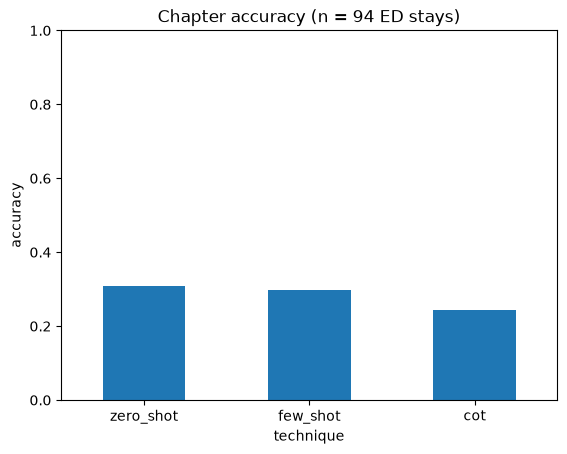

In [17]:
# What: compare the three prompts at a glance (the slide-9 chart).
summary.accuracy.plot.bar(rot=0, ylim=(0, 1), title=f"Chapter accuracy (n = {len(eval_df)} ED stays)")
plt.ylabel("accuracy"); plt.show()

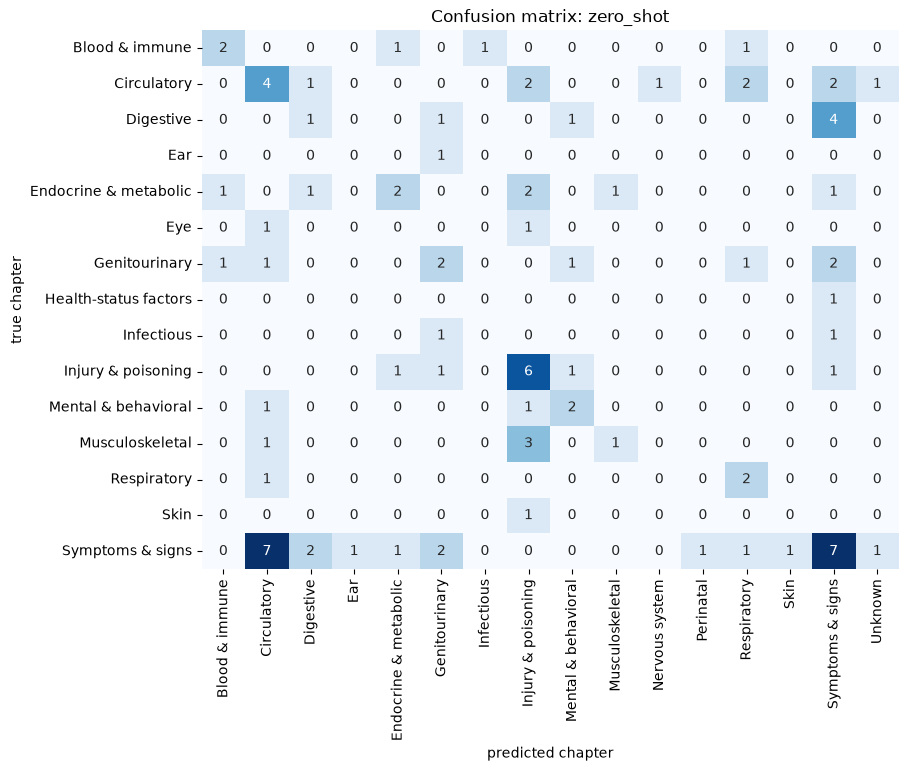

In [18]:
# What: for the best prompt, which chapters get confused with which (as in Series 9).
# You should see: a heatmap; correct answers lie on the diagonal.
best = summary.accuracy.idxmax()
cm = pd.crosstab(results.loc[results.technique == best, "true_chapter"],
                 results.loc[results.technique == best, "pred_chapter"])
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title(f"Confusion matrix: {best}"); plt.ylabel("true chapter"); plt.xlabel("predicted chapter"); plt.show()

## Results

The results are somewhat surprising: **no prompt clearly beats zero-shot.** Zero-shot scored 31% chapter accuracy, few-shot 30% and chain-of-thought 24%.

**The small sample shows in these results.** We score only 94 stays from 29 patients, so the 95% interval on any one accuracy is roughly ±10 points, wider than every gap between the prompts. About 26% of the scored stays (24 of 94) have a primary diagnosis in "Symptoms & signs", so always guessing that chapter would score about 26%. Zero-shot and few-shot are only about 5 points above that trivial guess, and CoT is slightly below it. A larger sample would be needed to tell whether any technique really helps.

**Few-shot invented fewer codes.** Showing three real examples cut the invented-code rate from 49% to 43% without changing accuracy. The examples seem to teach the code format more than the diagnosis.

**Chain-of-thought made things worse.** It had the lowest accuracy and the most invented codes (60%), it took about 5× as long as zero-shot (about 7 minutes versus 1.5), and 5% of its answers ran past the length cap and failed to parse. For a 3B model, writing reasoning first doesn't produce better answers.

**The confusion matrix shows where the errors come from.** The largest error is true "Symptoms & signs" predicted as "Circulatory" (7 stays): the model names a heart condition for a complaint like chest pain, while the ED recorded only the symptom because the workup didn't confirm a cause. The reverse also happens: 4 "Digestive" stays were predicted as "Symptoms & signs". Much of the error comes from the labels themselves, not only from the model.

## Step 7: Limitations & responsible use

- **Labels are billing codes** assigned after the workup, not a gold-standard diagnosis. The ED often records a symptom when it can't confirm a cause.
- **Small sample:** 94 scored stays from 29 patients, so the estimates are noisy.
- **One hospital:** Beth Israel Deaconess. Coding habits and patient mix may not carry over.
- **One small model** (3B parameters, 4-bit), one seed. A larger model may behave differently.
- **Reasoning can be unfaithful:** CoT explanations read as plausible but can invent findings, and the model sometimes answers in ICD-9.
- **Decision support only.** A tool like this could draft a likely chapter for a clinician to check, never replace triage judgment. Confident-looking output invites automation bias (10.2), so any deployment would need human review and monitoring.

## AI usage

**Claude Opus 5.5** (`claude-opus-5-5`, Anthropic) in Claude Code: helped write code for this tutorial